In [1]:
import sys
import os
from gaussian_beam import *
from adjoint import *
from plot import *
import time
import shutil
from datetime import timedelta

# set plot line thickness to 3
plt.rcParams['lines.linewidth'] = 5

In [2]:
params=initialize_variables_from_file('base/delta_f_targ_0.05_f_init_0.045_ell_0_wl_1e-06_f_num_25_conic_-1_nr_1000_r_maxf_5_nzf_501_dz_0.02_steps_5000_lr_5e-11_delta_1_tol_0.01_sg_0_order_0.txt')

In [3]:
f_targ = params["f_targ"]  # focal length of lens
ell = 0  # order of Bessel J function
f_init = params["f_init"]  # initial mirror focal length
conic = params["conic"]

# Beam Parameters
wl = params["wl"]  # wavelength
k0 = 2 * np.pi / wl  # k=2*pi/wavelength
fn = params["f_num"]  # f#
w0 = f_init / (2 * fn)  # initial spot size
rmax = params["r_maxf"] * w0  # the max value of r
nr = params["nr"]  # number of points in r
zR = np.pi * w0**2 / wl  # Initial rayleigh length
wR = 2 / np.pi * fn * wl  # Diffraction limited spot size

# Distance parameters
dz = params["dz"]
nzf = params["nzf"]
zF = np.linspace(f_targ - dz, f_targ + dz, nzf)
fl = len(zF) // 2  # focal length index

# Guess parameters
OoM = math.floor(math.log(w0**2, 10))  # order of magnitude of w0^2
w_guess = 10**OoM  # guess for the spot size
steps = params["steps"]  # max number of steps algorithm is allowed
lr = params["lr"]  # learning rate
tol = params["tol"]  # tolerance
delta = params["delta"]  # weighting function in r

In [4]:
[r, k] = DHTarrays(nr, rmax, ell)
[T_R2K, T_K2R] = DHTtransformMatrix(nr, rmax, ell)

# Initial propagation
phi_I = 1j * np.exp(-((r / w0) ** 2))
zm_t = create_starting_optic(r, 2 * f_targ)  # target mirror
ftf_t = forward_propagation(
    w0, r, k, phi_I, T_R2K, T_K2R, zF, zm_t
)  # Target profile defined using target mirror

a_n = create_initial_coeff(rmax, 2 * f_targ)
rho = r / rmax
Z_fit = calc_Z(rho)
Z_plus = calc_Z_plus(Z_fit)
zm_z = generate_optic(a_n, Z_fit)  # initial mirror
ftf_z = forward_propagation(
    w0, r, k, phi_I, T_R2K, T_K2R, zF, zm_z
)  # initial profile defined

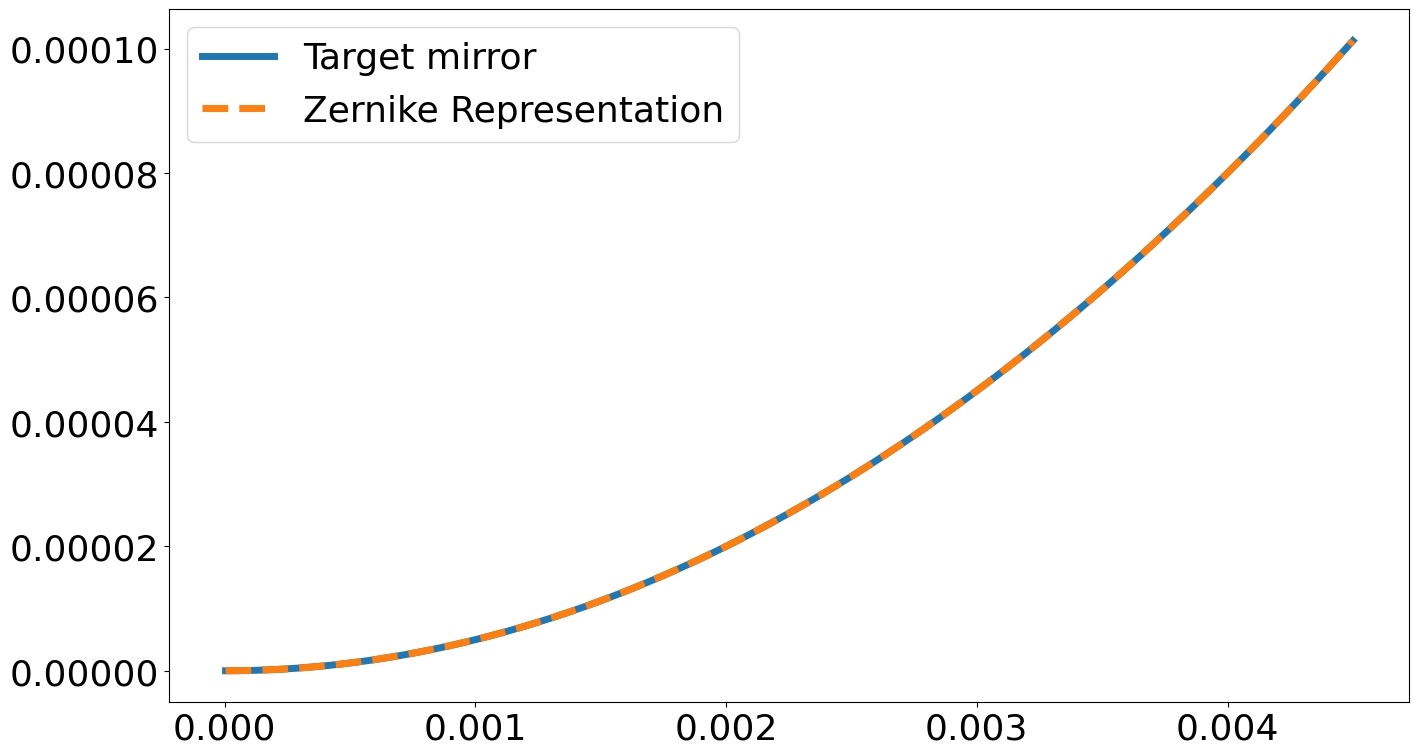

In [5]:
plt.plot(r,zm_t, label="Target mirror")
plt.plot(r,zm_z, label="Zernike Representation", linestyle="--")
plt.legend()
plt.()

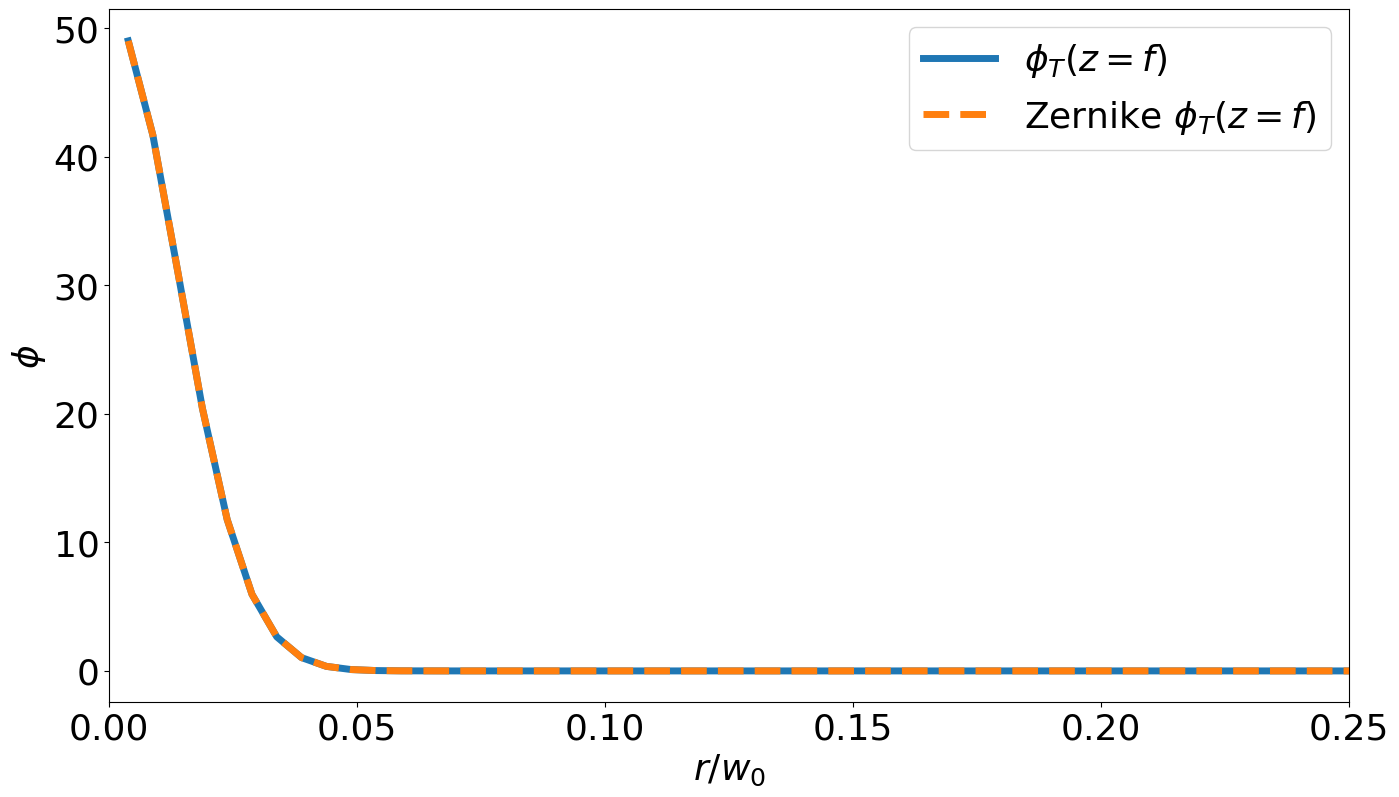

In [6]:
plt.plot(r / w0, np.real(ftf_t[:, fl]), label=r"$\phi_T(z=f)$")
plt.plot(r / w0, np.real(ftf_z[:, fl]), label=r"Zernike $\phi_T(z=f)$", linestyle="--")
plt.xlim(0,0.25)
plt.legend()
plt.ylabel(r"$\phi$")
plt.xlabel(r"$r/w_0$")
plt.savefig("zernike_comp_transverse.png")
plt.show()

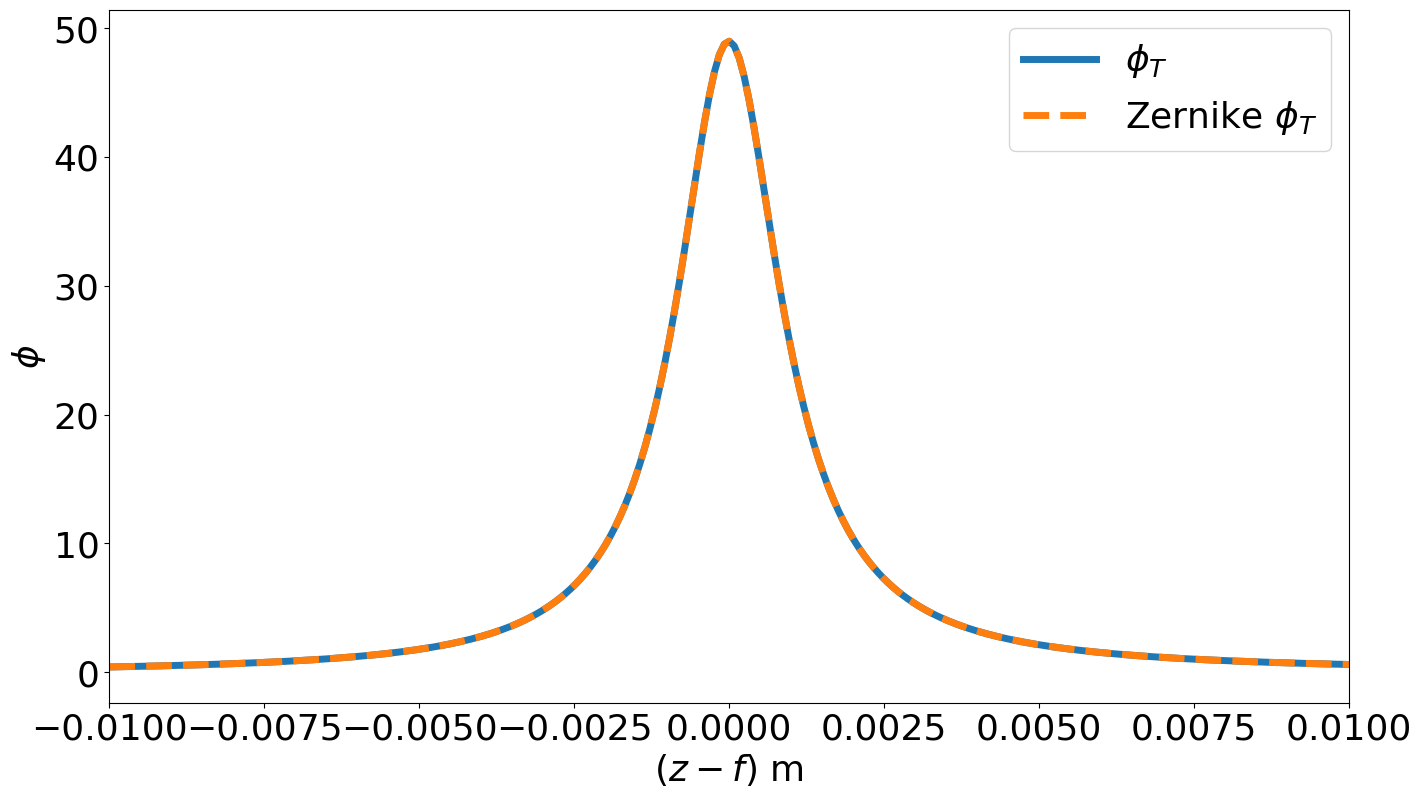

In [9]:
plt.plot(zF - f_targ, np.real(ftf_t[0, :]), label=r"$\phi_T$")
plt.plot(zF - f_targ, np.real(ftf_z[0, :]), label=r"Zernike $\phi_T$", linestyle="--")
plt.legend()
plt.ylabel(r"$\phi$")
plt.xlabel(r"$(z-f)$ m")
plt.xlim(-0.01,0.01)
plt.savefig("zernike_comp_longitudinal.png")
plt.show()